In [17]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import cv2

In [10]:
#Insert path to dataset
path = ''

metadata = pd.read_json( path + 'Fundus_CIMT_2903_Dataset/data_info.json')
retina_images = glob(path + 'Fundus_CIMT_2903_Dataset/images/*.png')

In [16]:
len(retina_images), metadata.shape

(4980, (8, 2903))

In [78]:
img_L = plt.imread( path + "Fundus_CIMT_2903_Dataset/images/704259001_L.png")
img_R = plt.imread(path + "Fundus_CIMT_2903_Dataset/images/704259001_R.png")
type(img_L), img_R.shape

(numpy.ndarray, (512, 512, 3))

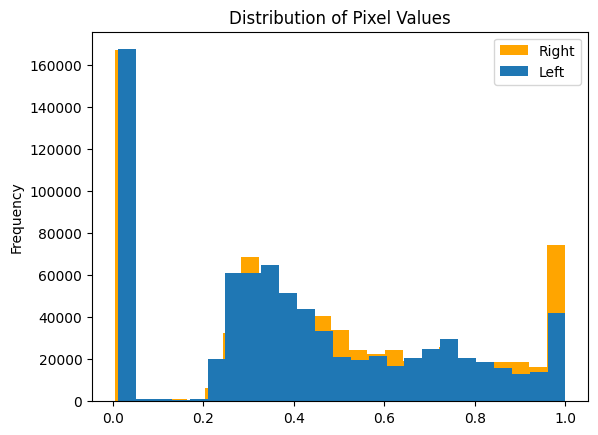

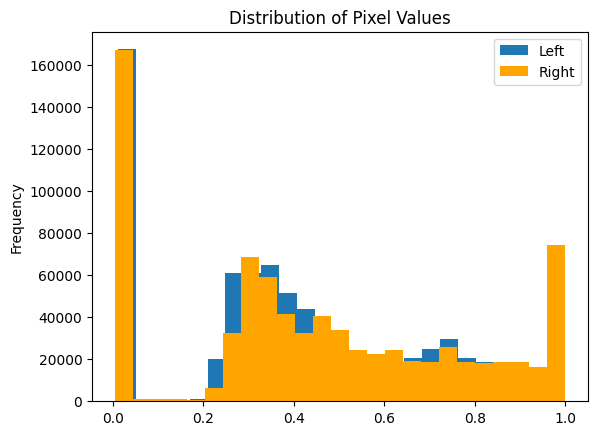

In [79]:
plt.figure()

pd.Series(img_R.flatten()).plot(kind='hist',
                                  bins=25,
                                  label='Right',
                                color='orange')

pd.Series(img_L.flatten()).plot(kind='hist',
                                  bins=25,
                                label='Left',
                                color='#1f77b4')

plt.title("Distribution of Pixel Values")
plt.legend()
plt.show()

plt.figure()

pd.Series(img_L.flatten()).plot(kind='hist',
                                  bins=25,
                                label='Left',
                                color="#1f77b4")
pd.Series(img_R.flatten()).plot(kind='hist',
                                  bins=25,
                                  label='Right',
                                color="orange")

plt.title("Distribution of Pixel Values")
plt.legend()
plt.show()

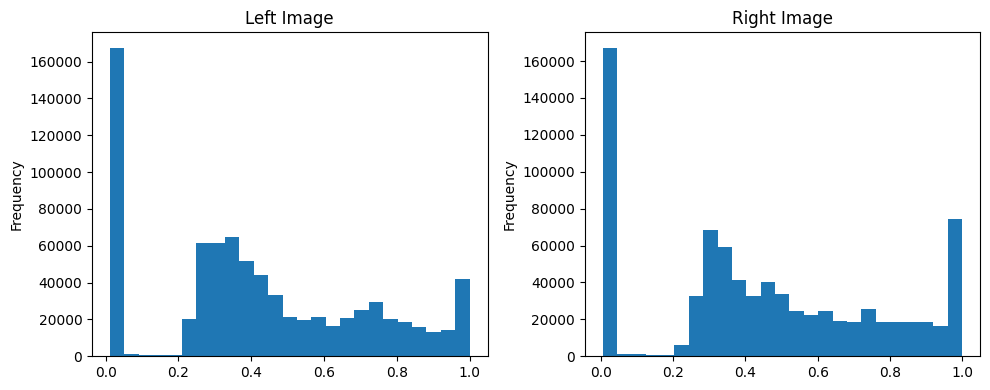

In [80]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

pd.Series(img_L.flatten()).plot(
    kind='hist', bins=25, ax=axes[0], title='Left Image'
)

pd.Series(img_R.flatten()).plot(
    kind='hist', bins=25, ax=axes[1], title='Right Image'
)

plt.tight_layout()
plt.show()


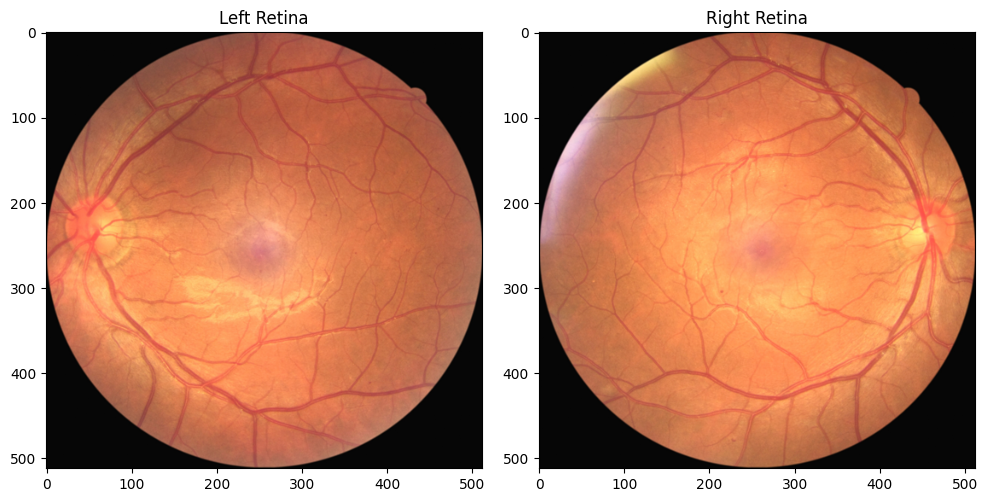

In [81]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img_L)
ax[0].set_title("Left Retina")

ax[1].imshow(img_R)
ax[1].set_title("Right Retina")

plt.tight_layout()
plt.show()



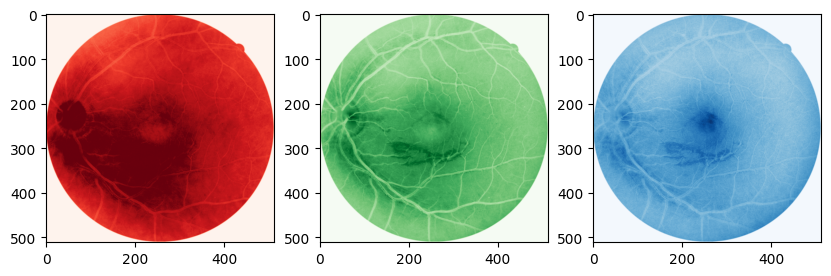

In [82]:
#Displaying 3 color channels sepretly
fig, ax = plt.subplots(1, 3, figsize=(10,10))
ax[0].imshow(img_L[:,:, 0], cmap="Reds")
ax[1].imshow(img_L[:,:, 1], cmap="Greens")
ax[2].imshow(img_L[:,:, 2], cmap="Blues")


plt.show()

In [87]:
raw_data = pd.DataFrame(metadata).T
raw_data.head()

,gender,thickness,label,group,True_age,age,right_eye,left_eye
2491006,0,0.8,0,1,63,0.684932,2491006_R.png,2491006_L.png
3730004,1,1.2,1,1,61,0.657534,3730004_R.png,3730004_L.png
3730006,1,1.2,1,1,64,0.69863,3730006_R.png,3730006_L.png
4738005,0,0.7,0,1,53,0.547945,4738005_R.png,4738005_L.png
6528003,0,1.2,1,1,66,0.726027,6528003_R.png,6528003_L.png


In [88]:
data = raw_data.drop(columns=['right_eye', 'left_eye'])

X_data = data.drop(columns=['thickness'])
y_data = data['thickness']

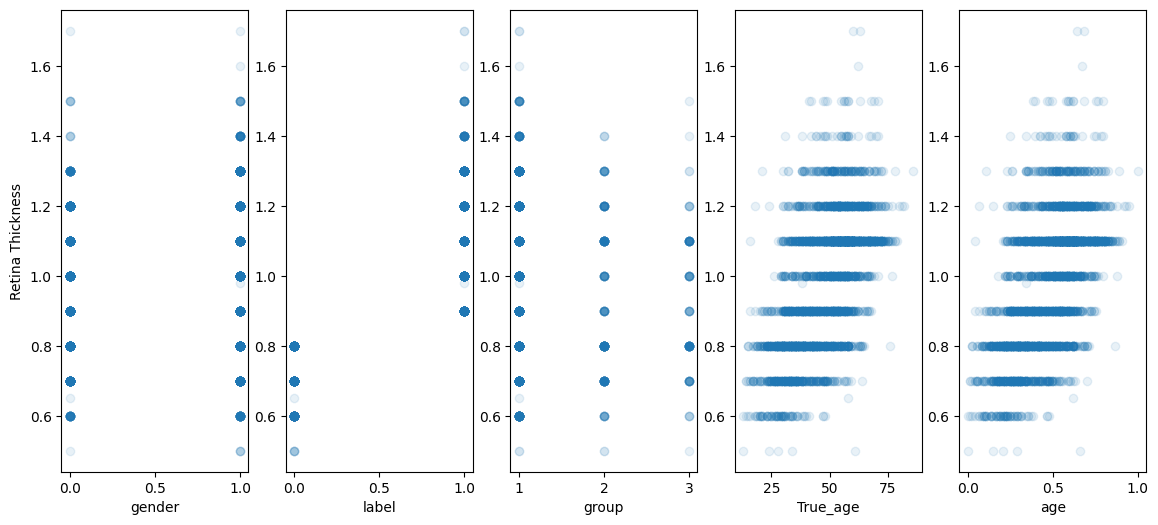

In [97]:
predictors = 5
fig, ax = plt.subplots(1, predictors, figsize=(14, 6))

for idx, columns in enumerate(X_data.columns):
  ax[idx].scatter(X_data[columns], y_data, alpha=0.1)
  ax[idx].set_xlabel(columns)
ax[0].set_ylabel('Retina Thickness')

plt.show()

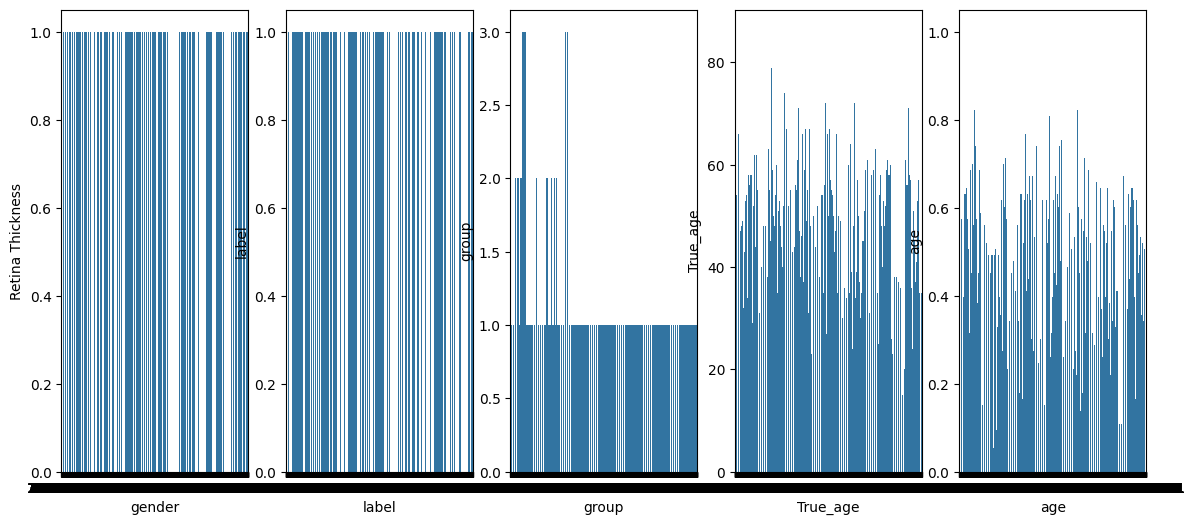

In [101]:
import seaborn as sns

predictors = 5
fig, ax = plt.subplots(1, predictors, figsize=(14, 6))

for idx, columns in enumerate(X_data.columns):
  sns.barplot(X_data[columns], ax=ax[idx])
  ax[idx].set_xlabel(columns)
ax[0].set_ylabel('Retina Thickness')

plt.show()

In [102]:
data.shape

(2903, 6)